In [1]:
# Load libraries and dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm 

df = pd.read_excel('Clean_Dataset.xlsx')

In [2]:
# 1. What is the structure of the data set (number of rows, columns, and data types)?
print('Data Types & Structure:')
df.info()

 

Data Types & Structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [ ]:
#1.1 column names 
print('\nColumn Names:')
print(df.columns.tolist())

 


Column Names:
['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


In [ ]:
#1.2 show first 6 rows
print('\nFirst 6 rows:')
print(df.head(6))

 


First 6 rows:
   Unnamed: 0   airline   flight source_city departure_time stops  \
0           0  SpiceJet  SG-8709       Delhi        Evening  zero   
1           1  SpiceJet  SG-8157       Delhi  Early_Morning  zero   
2           2   AirAsia   I5-764       Delhi  Early_Morning  zero   
3           3   Vistara   UK-995       Delhi        Morning  zero   
4           4   Vistara   UK-963       Delhi        Morning  zero   
5           5   Vistara   UK-945       Delhi        Morning  zero   

    arrival_time destination_city    class  duration  days_left  price  
0          Night           Mumbai  Economy      2.17          1   5953  
1        Morning           Mumbai  Economy      2.33          1   5953  
2  Early_Morning           Mumbai  Economy      2.17          1   5956  
3      Afternoon           Mumbai  Economy      2.25          1   5955  
4        Morning           Mumbai  Economy      2.33          1   5955  
5      Afternoon           Mumbai  Economy      2.33          1

In [ ]:
#1.3 show last 6 rows
print('\nLast 6 rows:')
print(df.tail(6))

 


Last 6 rows:
        Unnamed: 0    airline  flight source_city departure_time stops  \
300147      300147  Air_India  AI-569     Chennai  Early_Morning   one   
300148      300148    Vistara  UK-822     Chennai        Morning   one   
300149      300149    Vistara  UK-826     Chennai      Afternoon   one   
300150      300150    Vistara  UK-832     Chennai  Early_Morning   one   
300151      300151    Vistara  UK-828     Chennai  Early_Morning   one   
300152      300152    Vistara  UK-822     Chennai        Morning   one   

       arrival_time destination_city     class  duration  days_left  price  
300147        Night        Hyderabad  Business     17.25         49  68739  
300148      Evening        Hyderabad  Business     10.08         49  69265  
300149        Night        Hyderabad  Business     10.42         49  77105  
300150        Night        Hyderabad  Business     13.83         49  79099  
300151      Evening        Hyderabad  Business     10.00         49  81585  
30015

In [ ]:
#1.4 print summary of data 
print('\nSummary of data:')
print(df.describe(include='all'))

 


Summary of data:
           Unnamed: 0  airline  flight source_city departure_time   stops  \
count   300153.000000   300153  300153      300153         300153  300153   
unique            NaN        6    1561           6              6       3   
top               NaN  Vistara  UK-706       Delhi        Morning     one   
freq              NaN   127859    3235       61343          71146  250863   
mean    150076.000000      NaN     NaN         NaN            NaN     NaN   
std      86646.852011      NaN     NaN         NaN            NaN     NaN   
min          0.000000      NaN     NaN         NaN            NaN     NaN   
25%      75038.000000      NaN     NaN         NaN            NaN     NaN   
50%     150076.000000      NaN     NaN         NaN            NaN     NaN   
75%     225114.000000      NaN     NaN         NaN            NaN     NaN   
max     300152.000000      NaN     NaN         NaN            NaN     NaN   

       arrival_time destination_city    class       durat

In [8]:
#1.5 no of rows and columns
print('\nDimensions (rows, columns):')
print(df.shape)

# Convert class to category
df['class'] = df['class'].astype('category')


Dimensions (rows, columns):
(300153, 12)


In [12]:
# 2. Find Missing values and handle
print('Missing values in each column:')
print(df.isnull().sum())

Missing values in each column:
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [ ]:
# 2.1 top 10flights data 
top_10_flights = df.sort_values(by='price', ascending=False).head(10)
top_10_flights[['airline', 'flight', 'source_city', 'destination_city', 'class', 'duration', 'days_left', 'price']]


,airline,flight,source_city,destination_city,class,duration,days_left,price
261377,Vistara,UK-772,Kolkata,Delhi,Business,13.50,3,123071
216096,Vistara,UK-811,Delhi,Kolkata,Business,10.92,5,117307
215859,Vistara,UK-809,Delhi,Kolkata,Business,21.08,1,116562
277345,Vistara,UK-870,Hyderabad,Mumbai,Business,16.42,3,115211
270999,Vistara,UK-772,Kolkata,Hyderabad,Business,9.50,17,114705
290568,Vistara,UK-832,Chennai,Mumbai,Business,15.08,5,114704
230092,Vistara,UK-996,Mumbai,Bangalore,Business,22.50,2,114523
219183,Vistara,UK-707,Delhi,Hyderabad,Business,27.42,2,114507
215858,Vistara,UK-809,Delhi,Kolkata,Business,21.08,1,114434
241599,Vistara,UK-996,Mumbai,Chennai,Business,15.42,3,111964


In [ ]:
# 2.2 Find (highest price flight)
topper = rank_flights[rank_flights['rank'] == 1][['flight', 'price', 'rank']]
print(topper)

        flight   price  rank
261377  UK-772  123071     1


In [ ]:
# 2.3 Average of top10 flights marks/price
avg_price_top10 = top10_flights['price'].mean()
print('Average price of top 10 flights:', avg_price_top10)

Average price of top 10 flights: 115698.8


In [ ]:
# 3 Highest price and duration
high_flights = df.sort_values(by='price', ascending=False)[['flight', 'price', 'duration']].copy()
high_flights['group'] = 'High'
print(high_flights.head(10))

        flight   price  duration group
261377  UK-772  123071     13.50  High
216096  UK-811  117307     10.92  High
215859  UK-809  116562     21.08  High
277345  UK-870  115211     16.42  High
270999  UK-772  114705      9.50  High
290568  UK-832  114704     15.08  High
230092  UK-996  114523     22.50  High
219183  UK-707  114507     27.42  High
215858  UK-809  114434     21.08  High
241599  UK-996  111964     15.42  High


In [ ]:
#3.1 Sort flights by price in ascending order (cheapest first)
cheapest_flights = df.sort_values(by='price', ascending=True)
#3.2 Show the top 10 cheapest flights including their airline
print(cheapest_flights[['airline', 'flight', 'price', 'duration']].head(10))


         airline   flight  price  duration
205012    Indigo   6E-605   1105      4.75
205754    Indigo   6E-605   1105     10.08
205024    Indigo  6E-6137   1105      8.83
204736   AirAsia   I5-517   1105      1.17
205023    Indigo  6E-6113   1105      8.67
203908   AirAsia   I5-517   1105      1.17
205022    Indigo   6E-605   1105      8.42
205021    Indigo  6E-7185   1105      7.92
206352  GO_FIRST   G8-504   1105      1.00
206353   AirAsia   I5-517   1105      1.17


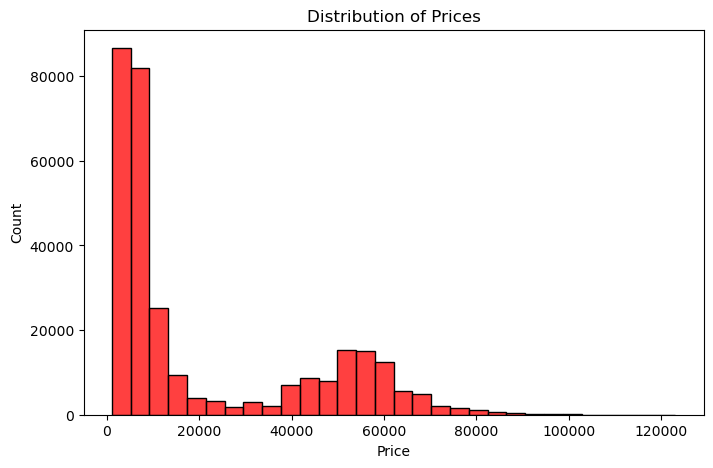

In [ ]:
# 4 Overall  (prices)
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=30, color='red', edgecolor='black')
plt.title('Distribution of Prices')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

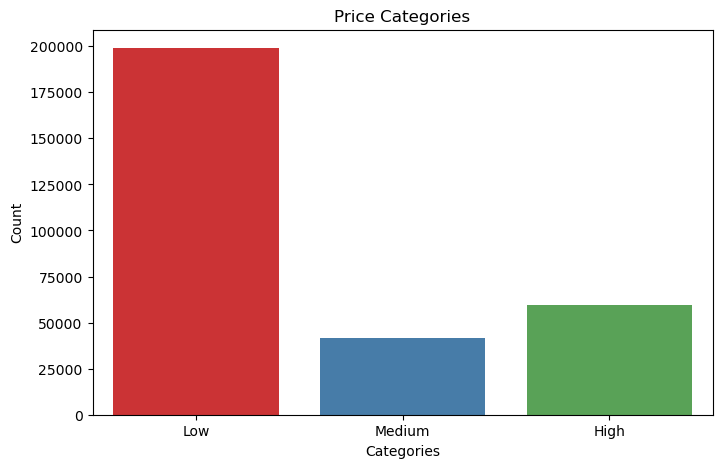

In [ ]:
# 5. (price categories)
df['price_groups'] = np.where(df['price'] >= 50000, 'High',
                              np.where(df['price'] >= 15000, 'Medium', 'Low'))

plt.figure(figsize=(8, 5))
sns.countplot(x='price_groups', data=df, hue='price_groups', order=['Low', 'Medium', 'High'], palette='Set1', legend=False)
plt.title('Price Categories')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.show()

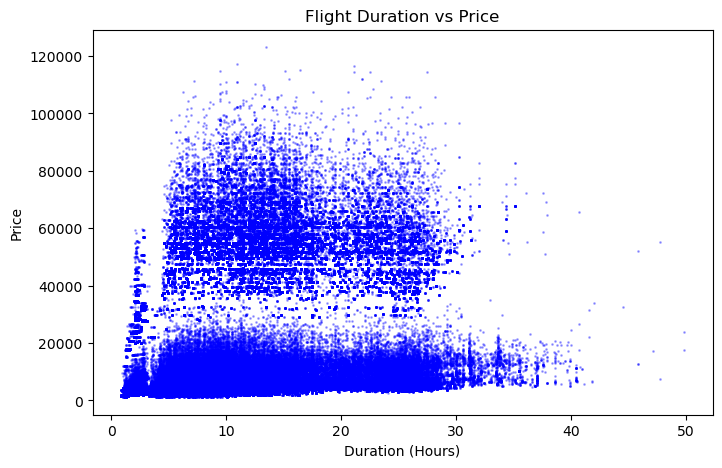

In [ ]:
# 6. (Duration vs Price)
plt.figure(figsize=(8, 5))
plt.scatter(df['duration'], df['price'], color='blue', alpha=0.3, s=1)
plt.title('Flight Duration vs Price')
plt.xlabel('Duration (Hours)')
plt.ylabel('Price')
plt.show()

      class         price
0  Business  52540.081124
1   Economy   6572.342383


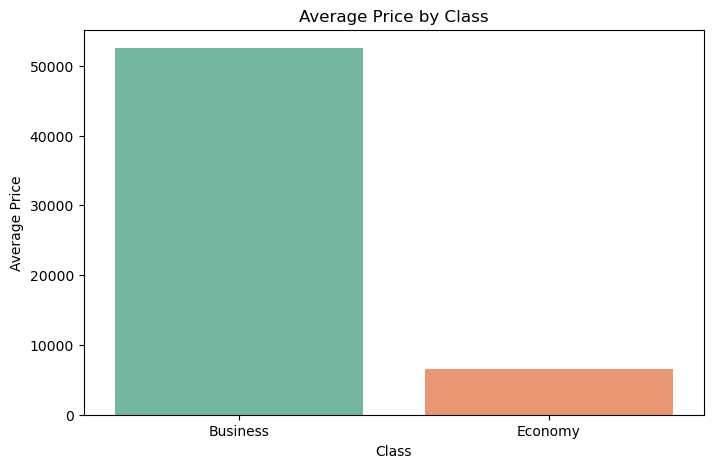

In [17]:
# 7 Find average by class
class_avg = df.groupby('class', observed=False)['price'].mean().reset_index()
print(class_avg)

plt.figure(figsize=(8, 5))
sns.barplot(x='class', y='price', data=class_avg, hue='class', palette='Set2', legend=False)
plt.title('Average Price by Class')
plt.xlabel('Class')
plt.ylabel('Average Price')
plt.show()

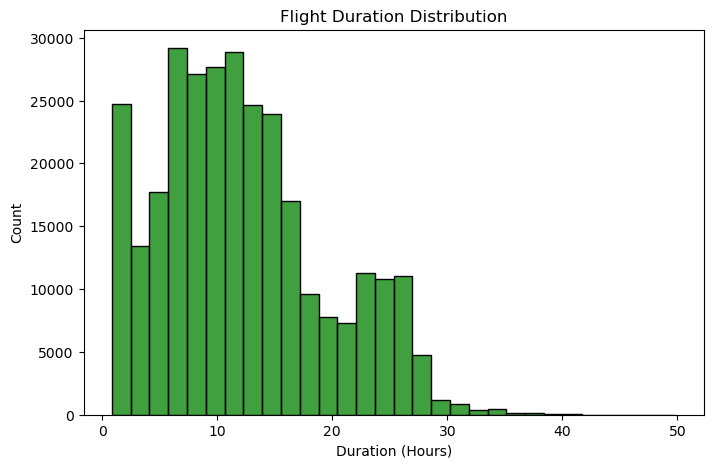

In [ ]:
# 8. (duration) distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['duration'], bins=30, color='green', edgecolor='black')
plt.title('Flight Duration Distribution')
plt.xlabel('Duration (Hours)')
plt.ylabel('Count')
plt.show()

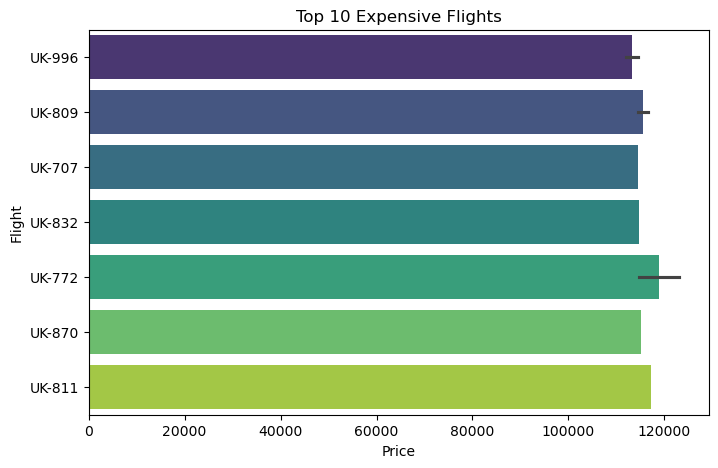

In [11]:
# 9. Top 10 flights
plt.figure(figsize=(8, 5))
sns.barplot(x='price', y='flight', data=top10_flights.sort_values(by='price'), hue='flight', palette='viridis', legend=False)
plt.title('Top 10 Expensive Flights')
plt.xlabel('Price')
plt.ylabel('Flight')
plt.show()

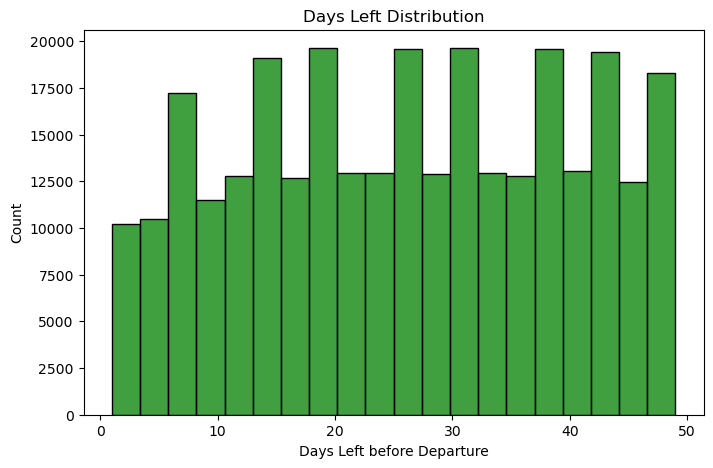

In [ ]:
# 10. (days left) distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['days_left'], bins=20, color='green', edgecolor='black')
plt.title('Days Left Distribution')
plt.xlabel('Days Left before Departure')
plt.ylabel('Count')
plt.show()

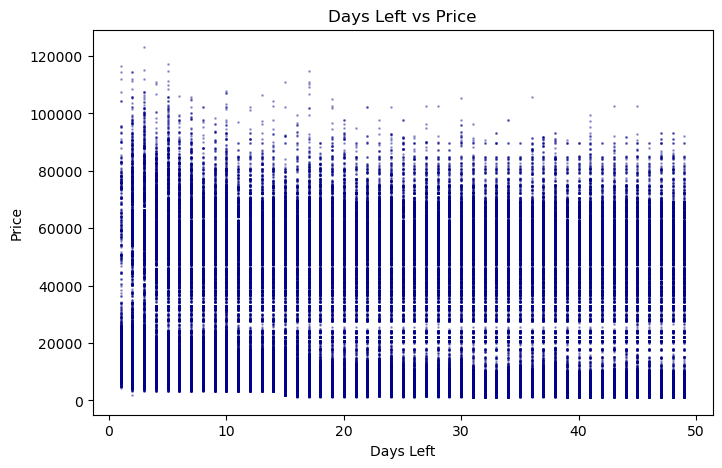

In [ ]:
# 11. (days left) vs (price)
plt.figure(figsize=(8, 5))
plt.scatter(df['days_left'], df['price'], color='darkblue', alpha=0.3, s=1)
plt.title('Days Left vs Price')
plt.xlabel('Days Left')
plt.ylabel('Price')
plt.show()

In [21]:
# 12. Flights with low duration but high price
short_expensive = df[(df['duration'] < 3) & (df['price'] >= 40000)][['flight', 'duration', 'price']]
print('Number of short but expensive flights:', len(short_expensive))
print(short_expensive.head(50))

Number of short but expensive flights: 370
        flight  duration  price
206671  UK-985      2.17  50264
206675  UK-977      2.25  53288
206713  UK-977      2.25  40296
206714  UK-963      2.33  40296
206715  UK-955      2.33  40296
206720  UK-927      2.08  44328
206726  UK-985      2.17  45896
206734  UK-945      2.33  49256
206740  UK-995      2.25  51496
206808  UK-977      2.25  40296
206809  UK-963      2.33  40296
206813  UK-955      2.33  44664
206823  UK-985      2.17  45896
206832  UK-933      2.17  51496
206916  UK-927      2.08  44328
206917  UK-945      2.33  44328
206923  UK-953      2.17  45336
206928  UK-985      2.17  50264
206943  UK-933      2.17  51496
206951  UK-977      2.25  53288
207031  UK-995      2.25  42424
207033  UK-945      2.33  44328
207035  UK-977      2.25  44664
207040  UK-941      2.33  46568
207064  UK-955      2.33  53288
207073  UK-985      2.17  58216
207143  UK-985      2.17  42312
207145  UK-927      2.08  44328
207172  UK-977      2.25  532

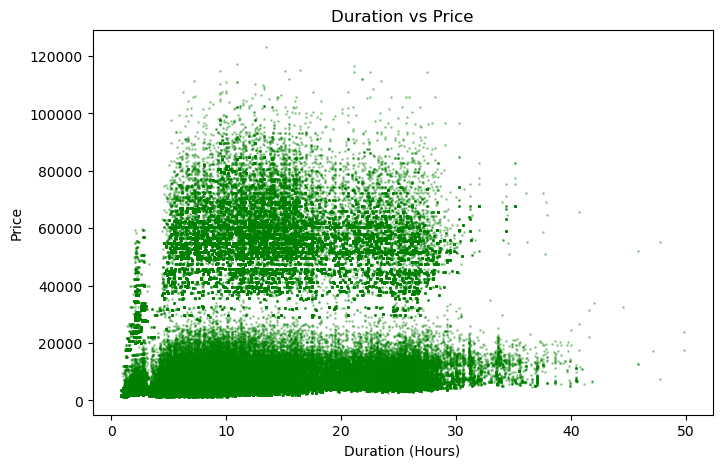

In [ ]:
# 12.1 Visualize of duration vs price 
plt.figure(figsize=(8, 5))
plt.scatter(df['duration'], df['price'], color='green', alpha=0.3, s=1)
plt.title('Duration vs Price')
plt.xlabel('Duration (Hours)')
plt.ylabel('Price')
plt.show()

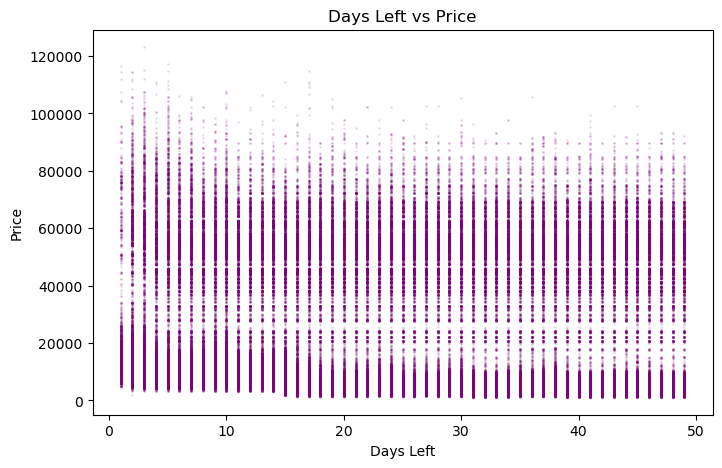

In [23]:
# 13. Does days left strongly predict price (assignment analogue)
plt.figure(figsize=(8, 5))
plt.scatter(df['days_left'], df['price'], color='purple', alpha=0.1, s=1)
plt.title('Days Left vs Price')
plt.xlabel('Days Left')
plt.ylabel('Price')
plt.show()

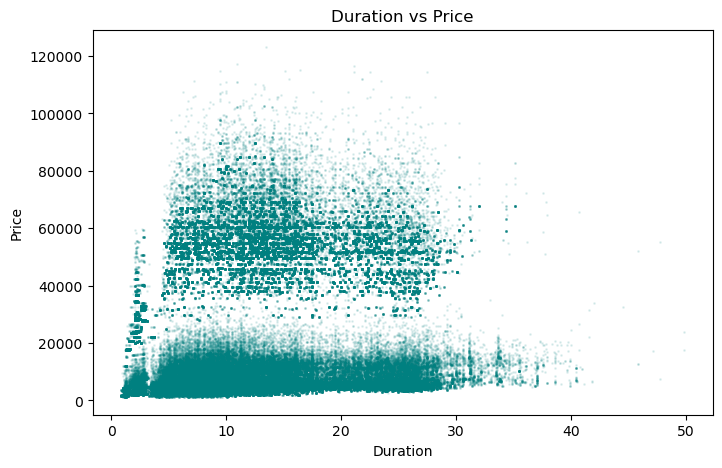

In [ ]:
# 14. Duration vs score  
plt.figure(figsize=(8, 5))
plt.scatter(df['duration'], df['price'], color='teal', alpha=0.1, s=1)
plt.title('Duration vs Price')
plt.xlabel('Duration')
plt.ylabel('Price')
plt.show()

         stops         price
0          one  22900.992482
1  two_or_more  14113.450775
2         zero   9375.938535


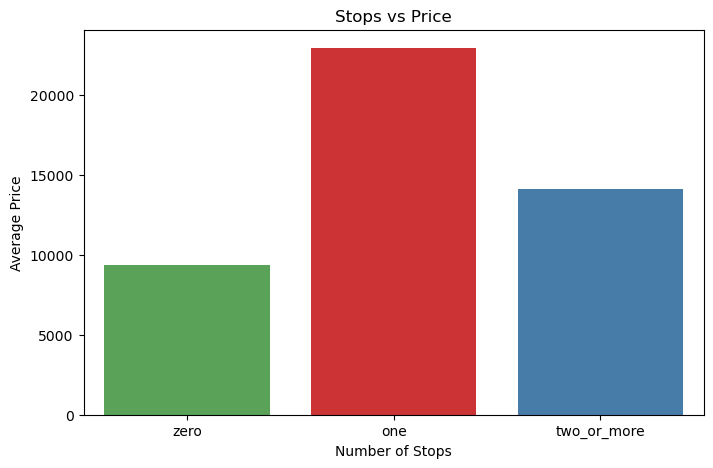

In [ ]:
# 15 Does having stops influence price  
stops_avg = df.groupby('stops')['price'].mean().reset_index()
print(stops_avg)

plt.figure(figsize=(8, 5))
sns.barplot(x='stops', y='price', data=stops_avg, hue='stops', order=['zero', 'one', 'two_or_more'], palette='Set1', legend=False)
plt.title('Stops vs Price')
plt.xlabel('Number of Stops')
plt.ylabel('Average Price')
plt.show()

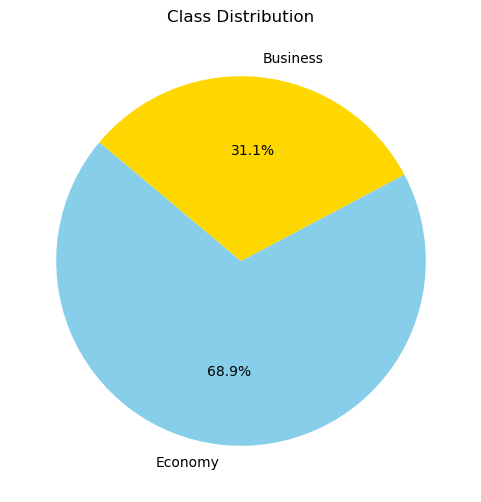

In [ ]:
# 16 What is the proportion of flights in each class category
class_counts = df['class'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', colors=['skyblue', 'gold'], startangle=140)
plt.title('Class Distribution')
plt.show()

     airline         price
0    AirAsia   4091.072742
1  Air_India  23507.019112
2   GO_FIRST   5652.007595
3     Indigo   5324.216303
4   SpiceJet   6179.278881
5    Vistara  30396.536302


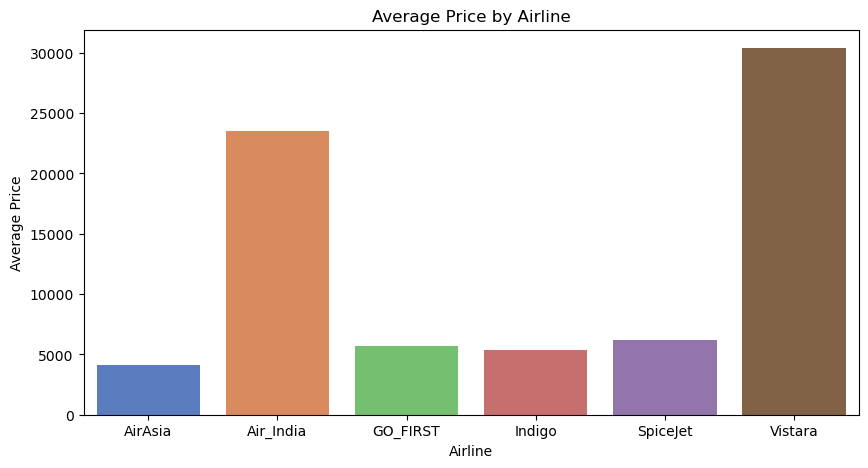

In [ ]:
# 17 How does average price differ across different airlines?
avg_airline_price = df.groupby('airline')['price'].mean().reset_index()
print(avg_airline_price)

plt.figure(figsize=(10, 5))
sns.barplot(x='airline', y='price', data=avg_airline_price, hue='airline', palette='muted', legend=False)
plt.title('Average Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Price')
plt.show()

      class   duration
0  Business  13.704274
1   Economy  11.550060


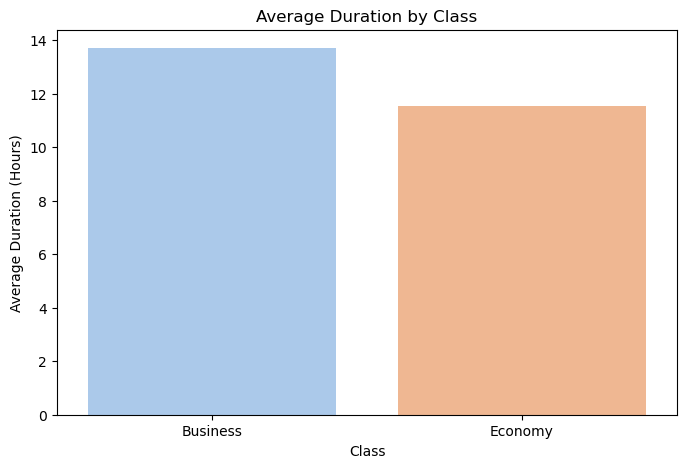

In [ ]:
# 18 How does duration vary by class
avg_class_duration = df.groupby('class', observed=False)['duration'].mean().reset_index()
print(avg_class_duration)

plt.figure(figsize=(8, 5))
sns.barplot(x='class', y='duration', data=avg_class_duration, hue='class', palette='pastel', legend=False)
plt.title('Average Duration by Class')
plt.xlabel('Class')
plt.ylabel('Average Duration (Hours)')
plt.show()

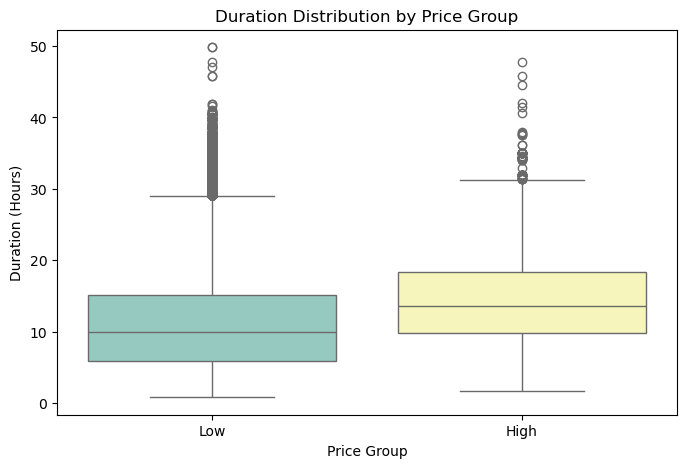

In [ ]:
# 19 How does the distribution of duration differ between high and low price flights
df['price_group_binary'] = np.where(df['price'] > 30000, 'High', 'Low')

plt.figure(figsize=(8, 5))
sns.boxplot(x='price_group_binary', y='duration', data=df, hue='price_group_binary', palette='Set3', legend=False)
plt.title('Duration Distribution by Price Group')
plt.xlabel('Price Group')
plt.ylabel('Duration (Hours)')
plt.show()

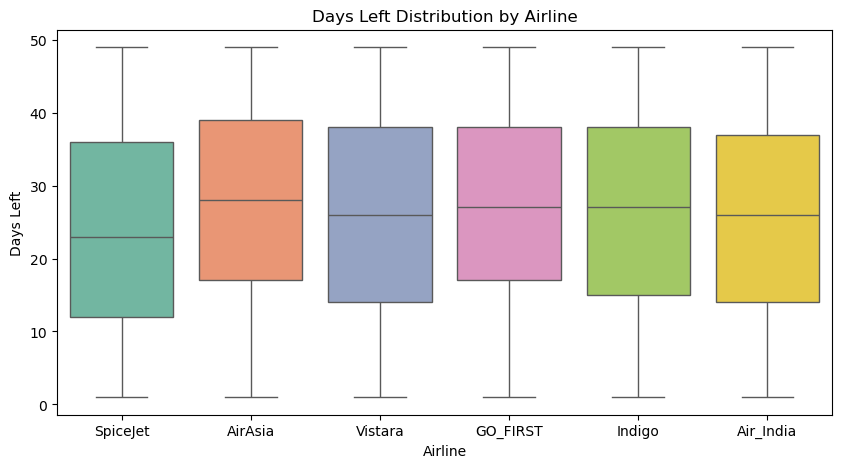

In [ ]:
# 20 How does days left vary across different airlines
plt.figure(figsize=(10, 5))
sns.boxplot(x='airline', y='days_left', data=df, hue='airline', palette='Set2', legend=False)
plt.title('Days Left Distribution by Airline')
plt.xlabel('Airline')
plt.ylabel('Days Left')
plt.show()

In [ ]:
# 21 How well do duration predict price using simple linear regression
X = sm.add_constant(df['duration'])
y = df['price']
model_simple = sm.OLS(y, X).fit()
print(model_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.042
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                 1.306e+04
Date:                Mon, 13 Jul 2026   Prob (F-statistic):               0.00
Time:                        15:16:21   Log-Likelihood:            -3.4300e+06
No. Observations:              300153   AIC:                         6.860e+06
Df Residuals:                  300151   BIC:                         6.860e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.301e+04     79.964    162.735      0.0

In [ ]:
# 22 Which variable among duration and days left has the strongest effect in the regression model
X_mult = sm.add_constant(df[['duration', 'days_left']])
y = df['price']
model_mult = sm.OLS(y, X_mult).fit()
print(model_mult.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.049
Model:                            OLS   Adj. R-squared:                  0.049
Method:                 Least Squares   F-statistic:                     7694.
Date:                Mon, 13 Jul 2026   Prob (F-statistic):               0.00
Time:                        15:16:28   Log-Likelihood:            -3.4289e+06
No. Observations:              300153   AIC:                         6.858e+06
Df Residuals:                  300150   BIC:                         6.858e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        1.68e+04    113.070    148.577      0.0

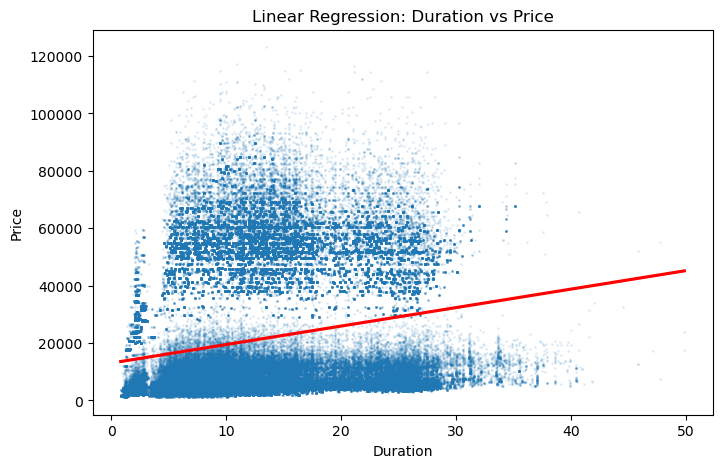

In [ ]:
# 23 What is the relationship between duration and price
plt.figure(figsize=(8, 5))
sns.regplot(x='duration', y='price', data=df, scatter_kws={'alpha': 0.1, 's': 1}, line_kws={'color': 'red'})
plt.title('Linear Regression: Duration vs Price')
plt.xlabel('Duration')
plt.ylabel('Price')
plt.show()